In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [4]:
df_all = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/all0818_2_all.csv')

In [5]:
odd = []
even = []
for i in range(0, df_all.shape[0]):
    if (df_all.iloc[i]['evid'] % 2 == 0):
        even.append(i)
    else:
        odd.append(i)

In [6]:
df1_all = df_all.iloc[odd]
df2_all = df_all.iloc[even]
df1_all.shape[0],df2_all.shape[0]

(1264691, 1263392)

In [7]:
df1_allreco = applyCut(df1_all, 'pts>15 and bs!=-9')
df2_allreco = applyCut(df2_all, 'pts>15 and bs!=-9')
df1_alltruth = applyCut(df1_all, 'pt>5 and b!=-9')
df2_alltruth = applyCut(df2_all, 'pt>5 and b!=-9')

Process sample 1

In [8]:
df1_allfake = applyCut(df1_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')
df1_match = applyCut(df1_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')

In [9]:
df1_allreco_pts_array = [ df1_allreco[(df1_allreco.pts>15) & (df1_allreco.pts<20)],\
                       df1_allreco[(df1_allreco.pts>20) & (df1_allreco.pts<25)],\
                       df1_allreco[(df1_allreco.pts>25) & (df1_allreco.pts<30)],\
                       df1_allreco[(df1_allreco.pts>30) & (df1_allreco.pts<40)] ]

df1_match_pts_array = [ df1_match[(df1_match.pts>15) & (df1_match.pts<20)],\
                       df1_match[(df1_match.pts>20) & (df1_match.pts<25)],\
                       df1_match[(df1_match.pts>25) & (df1_match.pts<30)],\
                       df1_match[(df1_match.pts>30) & (df1_match.pts<40)],\
                       df1_match[(df1_match.pts>40) & (df1_match.pts<60)] ]

df1_allfake_pts_array = [ df1_allfake[(df1_allfake.pts>15) & (df1_allfake.pts<20)],\
                       df1_allfake[(df1_allfake.pts>20) & (df1_allfake.pts<25)],\
                       df1_allfake[(df1_allfake.pts>25) & (df1_allfake.pts<30)],\
                       df1_allfake[(df1_allfake.pts>30) & (df1_allfake.pts<40)],\
                       df1_allfake[(df1_allfake.pts>40) & (df1_allfake.pts<60)]  ]

In [10]:
rc1_allreco_bs_vs_pts_array = []
rc1_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df1_allreco_pts_array)):
    rc1_allreco_bs_vs_pts_array.append(getRcAndErr(df1_allreco_pts_array[i], 'bs')[0])
    rc1_err_allreco_bs_vs_pts_array.append(getRcAndErr(df1_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df1_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df1_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df1_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df1_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df1_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df1_allfake_pts_array[i], 'bs')[1])

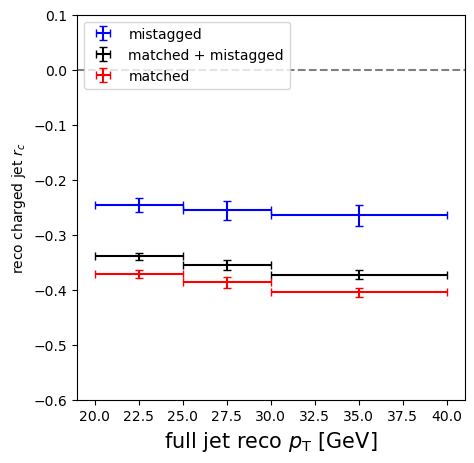

In [11]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_allfake_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array[1:-1], capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([22.5, 27.5, 35], rc1_allreco_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc1_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [12]:
rc1_allreco_bs_vs_pts_array

[-0.3546482052955329,
 -0.3393272996868273,
 -0.3549835170019773,
 -0.37246102157132954]

In [13]:
rc1_err_allreco_bs_vs_pts_array

[0.005486106781625499,
 0.006729035437129376,
 0.008654073184672319,
 0.007853832430826192]

In [14]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [16]:
b1_fake_array = []
b1_err_fake_array = []
for i in range(0,5):
    df1_fake_pts = df1_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df1_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df1_fake_pts['ws'], density=True)
    b1_fake_array.append(y_fake_rec/sum(y_fake_rec))
    b1_err_fake_array.append(yerr_fake_rec/sum(y_fake_rec))

In [17]:
b1_fake_array

[array([0.63105657, 0.36894343]),
 array([0.62312688, 0.37687312]),
 array([0.62780414, 0.37219586]),
 array([0.63250082, 0.36749918]),
 array([0.64577128, 0.35422872])]

In [18]:
df1_match_pt_array = [ df1_match[(df1_match.pt>15) & (df1_match.pt<20)],\
                       df1_match[(df1_match.pt>20) & (df1_match.pt<25)],\
                       df1_match[(df1_match.pt>25) & (df1_match.pt<30)],\
                       df1_match[(df1_match.pt>30) & (df1_match.pt<40)],\
                       df1_match[(df1_match.pt>40) & (df1_match.pt<60)]  ]

In [19]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df1_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df1_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df1_match_pt_array[i], 'bs')[1])

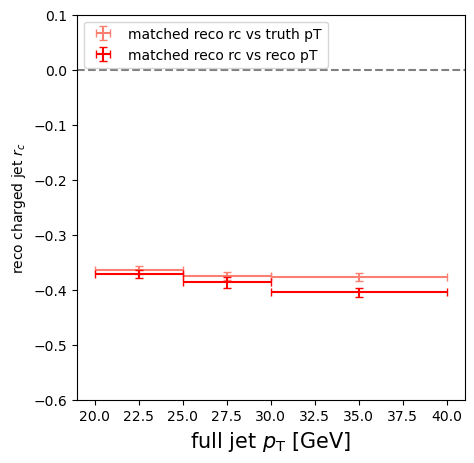

In [20]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='salmon', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched reco rc vs reco pT')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [25]:
b1_allreco_array = []
b1_err_allreco_array = []
for i in range(0,4):
    df1_allreco_pts = df1_allreco_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df1_allreco_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df1_allreco_pts['ws'], density=True)
    b1_allreco_array.append(y_reco/sum(y_reco))
    b1_err_allreco_array.append(yerr_reco/sum(y_reco))

In [26]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df1_allreco['pts'], bins=binedges, weights=df1_allreco['ws'])
match, _ = np.histogram(df1_allreco[(df1_allreco.pt!=-9) & (df1_allreco.b!=-9) & (df1_allreco.distance1<0.02) & (df1_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df1_allreco[(df1_allreco.pt!=-9) & (df1_allreco.b!=-9) & (df1_allreco.distance1<0.02) & (df1_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_2098828/2916068059.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [27]:
eff4

array([       nan,        nan, 0.69823058, 0.74487431, 0.75884395,
       0.76856031, 0.76624944])

In [28]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.30176942, 0.25512569, 0.24115605, 0.23143969, 0.23375056])

Process sample 2

In [31]:
df2_allfake = applyCut(df2_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')
df2_match = applyCut(df2_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')

In [32]:
df2_allreco_pts_array = [ df2_allreco[(df2_allreco.pts>15) & (df2_allreco.pts<20)],\
                       df2_allreco[(df2_allreco.pts>20) & (df2_allreco.pts<25)],\
                       df2_allreco[(df2_allreco.pts>25) & (df2_allreco.pts<30)],\
                       df2_allreco[(df2_allreco.pts>30) & (df2_allreco.pts<40)] ]

df2_match_pts_array = [ df2_match[(df2_match.pts>15) & (df2_match.pts<20)],\
                       df2_match[(df2_match.pts>20) & (df2_match.pts<25)],\
                       df2_match[(df2_match.pts>25) & (df2_match.pts<30)],\
                       df2_match[(df2_match.pts>30) & (df2_match.pts<40)],\
                       df2_match[(df2_match.pts>40) & (df2_match.pts<60)] ]

df2_allfake_pts_array = [ df2_allfake[(df2_allfake.pts>15) & (df2_allfake.pts<20)],\
                       df2_allfake[(df2_allfake.pts>20) & (df2_allfake.pts<25)],\
                       df2_allfake[(df2_allfake.pts>25) & (df2_allfake.pts<30)],\
                       df2_allfake[(df2_allfake.pts>30) & (df2_allfake.pts<40)],\
                       df2_allfake[(df2_allfake.pts>40) & (df2_allfake.pts<60)] ]

In [33]:
rc2_allreco_bs_vs_pts_array = []
rc2_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df2_allreco_pts_array)):
    rc2_allreco_bs_vs_pts_array.append(getRcAndErr(df2_allreco_pts_array[i], 'bs')[0])
    rc2_err_allreco_bs_vs_pts_array.append(getRcAndErr(df2_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df2_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df2_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df2_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df2_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df2_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df2_allfake_pts_array[i], 'bs')[1])

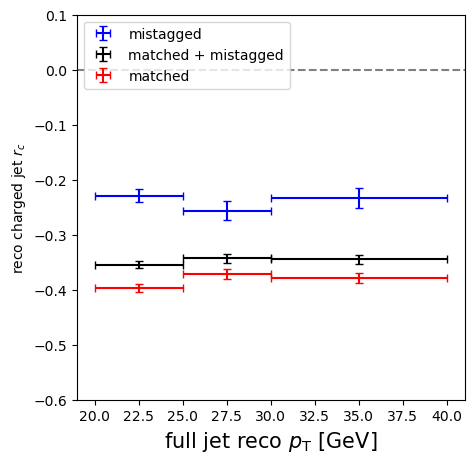

In [34]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_allfake_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array[1:-1], capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([22.5, 27.5, 35], rc2_allreco_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc2_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [35]:
df2_allreco_pts_array = [ df2_allreco[(df2_allreco.pts>15) & (df2_allreco.pts<20)],\
                       df2_allreco[(df2_allreco.pts>20) & (df2_allreco.pts<25)],\
                       df2_allreco[(df2_allreco.pts>25) & (df2_allreco.pts<30)],\
                       df2_allreco[(df2_allreco.pts>30) & (df2_allreco.pts<40)],\
                       df2_allreco[(df2_allreco.pts>40) & (df2_allreco.pts<60)] ]

In [36]:
b2_allreco_array = []
for i in range(0,5):
    df2_allreco_pts = df2_allreco_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df2_allreco_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df2_allreco_pts['ws'], density=True)
    b2_allreco_array.append(y_reco/sum(y_reco))

In [ ]:
def subtractFake(data, fake_rate, fake_dist):
    corrected = (data - fake_rate * fake_dist)/(1 - fake_rate)
    return corrected

In [53]:
b2_fakesubtracted_array = []
b2_err_fakesubtracted_array = []
rc_fakesubtracted_array = []
rc_err_fakesubtracted_array = []
for i in range(0,4):
    print(i)
    #print(b2_allreco_array[i])
    #print(getRc(data_array[i]))
    b2_fakesubtracted = subtractFake(b2_allreco_array[i], fake_rate_array[i], b1_fake_array[i])
    b2_fakesubtracted_array.append(b2_fakesubtracted)
    b2_err_fakesubtracted = np.sqrt(b1_err_allreco_array[i]**2+(fake_rate_array[i]*b1_err_fake_array[i])**2)
    b2_err_fakesubtracted_array.append(b2_err_fakesubtracted)
    print(b2_fakesubtracted)
    nos = b2_fakesubtracted[0]
    nss = b2_fakesubtracted[1]
    rc_fakesubtracted = (nss-nos) / (nss+nos)
    rc_fakesubtracted_array.append(rc_fakesubtracted)
    rc_err_fakesubtracted = 2*b2_err_fakesubtracted[0]
    rc_err_fakesubtracted_array.append(rc_err_fakesubtracted)

0
[0.68520174 0.31479826]
1
[0.69571855 0.30428145]
2
[0.68549662 0.31450338]
3
[0.68441378 0.31558622]


In [38]:
reweight_array = []
for i in range(0,5):
    reweight_array.append((b2_fakesubtracted_array[i]/sum(b2_fakesubtracted_array[i]))/(b1_match_array[i]/sum(b1_match_array[i])))

In [39]:
reweight_array

[array([0.9826209 , 1.04003841]),
 array([1.01475441, 0.9678252 ]),
 array([0.98876999, 1.02538348]),
 array([0.97437883, 1.06047446]),
 array([0.98155141, 1.0419168 ])]

Reweight sample 1

In [40]:
r = []
for i in range(0, df1_match.shape[0]):
    if (df1_match.iloc[i]['pts'] > 15 and df1_match.iloc[i]['pts'] < 20):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df1_match.iloc[i]['pts'] > 20 and df1_match.iloc[i]['pts'] < 25):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df1_match.iloc[i]['pts'] > 25 and df1_match.iloc[i]['pts'] < 30):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df1_match.iloc[i]['pts'] > 30 and df1_match.iloc[i]['pts'] < 40):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df1_match.iloc[i]['pts'] > 40 and df1_match.iloc[i]['pts'] < 60):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df1_match.iloc[i]['pts'])
df1_match['r'] = r #

anomaly reco pT: 72.52834643481873
anomaly reco pT: 69.20280354409849
anomaly reco pT: 65.41875767926956
anomaly reco pT: 63.5635618687876
anomaly reco pT: 60.70405679752255
anomaly reco pT: 61.62417163475988
anomaly reco pT: 64.13921004167145
anomaly reco pT: 63.26741775990175
anomaly reco pT: 61.66260468509
anomaly reco pT: 68.20950948777836
anomaly reco pT: 64.79185276926283
anomaly reco pT: 67.67916057471213
anomaly reco pT: 60.97632282080004
anomaly reco pT: 61.31205088824613
anomaly reco pT: 60.44839571472132
anomaly reco pT: 63.743074889567566
anomaly reco pT: 60.69513234622628
anomaly reco pT: 61.34609380116305
anomaly reco pT: 61.09680751848405
anomaly reco pT: 60.124260268608055
anomaly reco pT: 66.07920844689404
anomaly reco pT: 72.12724988655242
anomaly reco pT: 61.617904529220354
anomaly reco pT: 62.09951013523031
anomaly reco pT: 60.770814548420525
anomaly reco pT: 64.27987105012923
anomaly reco pT: 60.58691218707716
anomaly reco pT: 60.55835051973054
anomaly reco pT: 60.

anomaly reco pT: 64.08562236600436
anomaly reco pT: 64.93416926029012
anomaly reco pT: 61.05879096894288
anomaly reco pT: 68.47349671162468
anomaly reco pT: 60.39386209416123
anomaly reco pT: 70.60481301466638
anomaly reco pT: 61.27075927467068
anomaly reco pT: 62.33010618089577
anomaly reco pT: 61.48135227562536
anomaly reco pT: 65.82096286698923
anomaly reco pT: 60.16648142744786
anomaly reco pT: 61.48477428793863
anomaly reco pT: 61.35241172160737
anomaly reco pT: 61.623658787806
anomaly reco pT: 63.68630467369636
anomaly reco pT: 61.0420800046792
anomaly reco pT: 65.86503873921983
anomaly reco pT: 62.748651998620346
anomaly reco pT: 63.315467822314
anomaly reco pT: 69.0080170143091
anomaly reco pT: 62.77952836825133
anomaly reco pT: 61.23192502996347
anomaly reco pT: 69.62337851303222
anomaly reco pT: 64.32160483968126
anomaly reco pT: 60.637812634246544
anomaly reco pT: 60.84079514528543
anomaly reco pT: 64.21013442822478
anomaly reco pT: 67.36879888740025
anomaly reco pT: 62.9746

anomaly reco pT: 63.53891500689442
anomaly reco pT: 60.80596760038595
anomaly reco pT: 62.07526353813313
anomaly reco pT: 63.622091916075554
anomaly reco pT: 62.68849892449056
anomaly reco pT: 63.856813148342056
anomaly reco pT: 64.54390375456094
anomaly reco pT: 61.89993898967301
anomaly reco pT: 61.54050062216641
anomaly reco pT: 63.0701915081883
anomaly reco pT: 62.806815230022586
anomaly reco pT: 62.257487437564045
anomaly reco pT: 61.9052307813125
anomaly reco pT: 60.4795316303653
anomaly reco pT: 64.38673346823187
anomaly reco pT: 62.59909357711763
anomaly reco pT: 62.249100391325335
anomaly reco pT: 65.63935748640763
anomaly reco pT: 61.57052639905158
anomaly reco pT: 65.63452740444238
anomaly reco pT: 67.97050177643628
anomaly reco pT: 60.321418129971306
anomaly reco pT: 64.67264870821674
anomaly reco pT: 66.3100393370608
anomaly reco pT: 62.67048617512035
anomaly reco pT: 63.06653282444113
anomaly reco pT: 60.59985727729846
anomaly reco pT: 60.60848614142319
anomaly reco pT: 6

anomaly reco pT: 61.91320649329229
anomaly reco pT: 62.02763691539056
anomaly reco pT: 60.43021994285771
anomaly reco pT: 60.58339646435569
anomaly reco pT: 60.1085547109631
anomaly reco pT: 62.276815974035536
anomaly reco pT: 66.44533781054326
anomaly reco pT: 63.68463542672588
anomaly reco pT: 60.85394978654469
anomaly reco pT: 60.205457932647455
anomaly reco pT: 60.59601728561899
anomaly reco pT: 71.5564976670423
anomaly reco pT: 62.51630404407221
anomaly reco pT: 65.15577783264492
anomaly reco pT: 63.30575710065207
anomaly reco pT: 60.864253861138174
anomaly reco pT: 64.93661242891321
anomaly reco pT: 63.71547128168069
anomaly reco pT: 61.05649428220351
anomaly reco pT: 62.12723015954889
anomaly reco pT: 60.38053158416362
anomaly reco pT: 67.56552461526218
anomaly reco pT: 61.19013118262872
anomaly reco pT: 71.78155726681177
anomaly reco pT: 67.27971049117492
anomaly reco pT: 67.92911315515096
anomaly reco pT: 65.35039982916463
anomaly reco pT: 61.48770064310772
anomaly reco pT: 62

anomaly reco pT: 60.297003804819006
anomaly reco pT: 63.14282384097735
anomaly reco pT: 61.8406991345663
anomaly reco pT: 61.55943740612141
anomaly reco pT: 61.7531847211547
anomaly reco pT: 69.91858423568362
anomaly reco pT: 64.03657111010568
anomaly reco pT: 61.00655668637862
anomaly reco pT: 63.61222406459784
anomaly reco pT: 60.06930452258172
anomaly reco pT: 61.169401283505024
anomaly reco pT: 62.90126569204071
anomaly reco pT: 66.49703319649919
anomaly reco pT: 62.53920611213664
anomaly reco pT: 66.30014165101711
anomaly reco pT: 61.421294994464986
anomaly reco pT: 65.52801068666415
anomaly reco pT: 61.07955530629504
anomaly reco pT: 60.28231377724256
anomaly reco pT: 60.6326467002201
anomaly reco pT: 69.50448843924988
anomaly reco pT: 68.69925248953022
anomaly reco pT: 63.23653333693943
anomaly reco pT: 68.34157839733261
anomaly reco pT: 60.88572957264588
anomaly reco pT: 62.22931624578364
anomaly reco pT: 63.62474170829925
anomaly reco pT: 60.07550711086496
anomaly reco pT: 60.

anomaly reco pT: 62.79088850791956
anomaly reco pT: 61.19903898933745
anomaly reco pT: 62.52423627656399
anomaly reco pT: 73.4440568647176
anomaly reco pT: 60.652606943175336
anomaly reco pT: 65.04075588835651
anomaly reco pT: 65.5832848561159
anomaly reco pT: 61.53881954540864
anomaly reco pT: 62.13518559018646
anomaly reco pT: 60.69222038907494
anomaly reco pT: 62.70684081165358
anomaly reco pT: 65.5901677755709
anomaly reco pT: 61.07194318713693
anomaly reco pT: 61.06176919109842
anomaly reco pT: 60.03974425084471
anomaly reco pT: 70.48234784512833
anomaly reco pT: 61.32765626416707
anomaly reco pT: 69.13508137350118
anomaly reco pT: 63.60234613972389
anomaly reco pT: 61.50592945610665
anomaly reco pT: 69.14586467852484
anomaly reco pT: 61.31693364130656
anomaly reco pT: 62.37902433453119
anomaly reco pT: 63.83065000207083
anomaly reco pT: 66.10922781719198
anomaly reco pT: 65.39618505395825
anomaly reco pT: 61.26514094037061
anomaly reco pT: 65.86353374976254
anomaly reco pT: 62.67

... (8 outputs left out)

anomaly reco pT: 63.2031272578349
anomaly reco pT: 62.77331512422263
anomaly reco pT: 61.93397339700892
anomaly reco pT: 78.41751368814755
anomaly reco pT: 63.689305368626606
anomaly reco pT: 61.59545676969519
anomaly reco pT: 62.192021929097095
anomaly reco pT: 62.42757641994802
anomaly reco pT: 63.2823201358372
anomaly reco pT: 65.16839288572858
anomaly reco pT: 64.25805241179208
anomaly reco pT: 61.56778441903951
anomaly reco pT: 63.41062403714498
anomaly reco pT: 62.17474511487226
anomaly reco pT: 70.58750614249152
anomaly reco pT: 64.09330914438137
anomaly reco pT: 61.5875714032188
anomaly reco pT: 64.46114269777789
anomaly reco pT: 63.55248980223248
anomaly reco pT: 64.84861617108066
anomaly reco pT: 62.49174063722683
anomaly reco pT: 67.91572242679797
anomaly reco pT: 62.43462612130306
anomaly reco pT: 69.32088044411722
anomaly reco pT: 60.34475584483712
anomaly reco pT: 64.52726918866097
anomaly reco pT: 64.50875761534424
anomaly reco pT: 60.62878586422036
anomaly reco pT: 60.0

anomaly reco pT: 61.30274472173585
anomaly reco pT: 60.0454083521636
anomaly reco pT: 62.24349080407023
anomaly reco pT: 61.418707768664426
anomaly reco pT: 64.81287462222492
anomaly reco pT: 63.35768921493341
anomaly reco pT: 67.82656416152147
anomaly reco pT: 66.53005701588037
anomaly reco pT: 62.040809567660105
anomaly reco pT: 62.80475649409336
anomaly reco pT: 66.38598164429443
anomaly reco pT: 61.329516117555855
anomaly reco pT: 71.97463925405842
anomaly reco pT: 60.47904352506056
anomaly reco pT: 62.87939288366758
anomaly reco pT: 62.35383926991477
anomaly reco pT: 61.44928764886637
anomaly reco pT: 62.58188659137122
anomaly reco pT: 60.40281460355144
anomaly reco pT: 60.51501427845438
anomaly reco pT: 62.84104181461162
anomaly reco pT: 60.53505481943202
anomaly reco pT: 62.51146075694849
anomaly reco pT: 62.92720062707237
anomaly reco pT: 61.230058260804185
anomaly reco pT: 61.17986018533829
anomaly reco pT: 60.89751291270303
anomaly reco pT: 64.08660688620527
anomaly reco pT: 

anomaly reco pT: 61.9593153591336
anomaly reco pT: 60.370597990893714
anomaly reco pT: 60.784599823398686
anomaly reco pT: 61.19037338325538
anomaly reco pT: 60.63835393576624
anomaly reco pT: 60.51753214475777
anomaly reco pT: 66.15216640408714
anomaly reco pT: 62.06116431538612
anomaly reco pT: 61.68857515135543
anomaly reco pT: 60.54196087041924
anomaly reco pT: 62.94561078044212
anomaly reco pT: 60.06967306235381
anomaly reco pT: 61.99437174434019
anomaly reco pT: 62.03916981769236
anomaly reco pT: 60.26121571816626
anomaly reco pT: 60.05120135317749
anomaly reco pT: 62.09137770933208
anomaly reco pT: 60.08253946067863
anomaly reco pT: 62.05456819355355
anomaly reco pT: 62.76109867726705
anomaly reco pT: 61.13937867497228
anomaly reco pT: 62.40263334740248
anomaly reco pT: 60.60516057696736
anomaly reco pT: 63.55874668392686
anomaly reco pT: 63.8592482432656
anomaly reco pT: 61.94400138108221
anomaly reco pT: 63.63798264044825
anomaly reco pT: 66.34544746706501
anomaly reco pT: 61.

/tmp/ipykernel_2098828/1025607542.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1_match['r'] = r #


In [41]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [42]:
df1_match_pt_array = [ df1_match[(df1_match.pt>15) & (df1_match.pt<20)],\
                       df1_match[(df1_match.pt>20) & (df1_match.pt<25)],\
                       df1_match[(df1_match.pt>25) & (df1_match.pt<30)],\
                       df1_match[(df1_match.pt>30) & (df1_match.pt<40)],\
                       df1_match[(df1_match.pt>40) & (df1_match.pt<60)]  ]
df1_match_pts_array = [ df1_match[(df1_match.pts>15) & (df1_match.pts<20)],\
                       df1_match[(df1_match.pts>20) & (df1_match.pts<25)],\
                       df1_match[(df1_match.pts>25) & (df1_match.pts<30)],\
                       df1_match[(df1_match.pts>30) & (df1_match.pts<40)],\
                       df1_match[(df1_match.pts>40) & (df1_match.pts<60)] ]

In [43]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df1_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df1_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df1_match_pt_array[i], 'bs')[1])

Obtain truth

In [45]:
df2_alltruth_pt_array = [ df2_alltruth[(df2_alltruth.pt>15) & (df2_alltruth.pt<20)],\
                       df2_alltruth[(df2_alltruth.pt>20) & (df2_alltruth.pt<25)],\
                       df2_alltruth[(df2_alltruth.pt>25) & (df2_alltruth.pt<30)],\
                       df2_alltruth[(df2_alltruth.pt>30) & (df2_alltruth.pt<40)] ]
# this is technically incorrect since
# df_all = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all0818_2_all.csv')
# df_alltruth = applyCut(df_all, 'pt>5 and b!=-9')
# and df_all include only jets that pass the detector-level cuts

In [46]:
rc2_truth_b_vs_pt_array = []
rc2_err_truth_b_vs_pt_array = []
for i in range(0, len(df2_alltruth_pt_array)):
    rc2_truth_b_vs_pt_array.append(getRcAndErr(df2_alltruth_pt_array[i], 'b')[0])
    rc2_err_truth_b_vs_pt_array.append(getRcAndErr(df2_alltruth_pt_array[i], 'b')[1])

Check closure

In [61]:
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
plt.rcParams['font.family'] = 'arial'
plt.rcParams['axes.unicode_minus'] = False

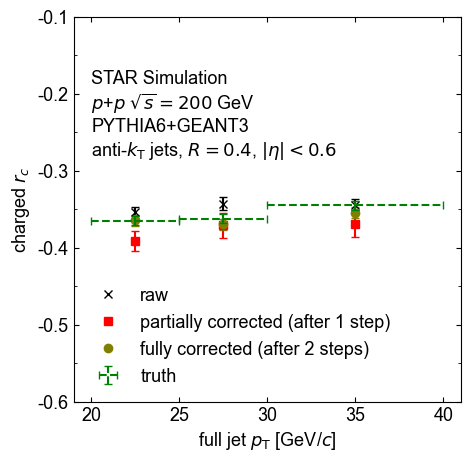

In [76]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc2_allreco_bs_vs_pts_array[1:], yerr=rc2_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none')
plt.errorbar([22.5, 27.5, 35], rc_fakesubtracted_array[1:], yerr=rc_err_fakesubtracted_array[1:], capsize=3, color='r', ls='none')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='olive', ls='none')
plt.plot([22.5, 27.5, 35], rc2_allreco_bs_vs_pts_array[1:], color='k', ls='none', marker='x', label='raw')
plt.plot([22.5, 27.5, 35], rc_fakesubtracted_array[1:], color='r', ls='none', marker='s', label='partially corrected (after 1 step)')
plt.plot([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], color='olive', ls='none', marker='o', label='fully corrected (after 2 steps)')
eb1 = plt.errorbar([22.5, 27.5, 35], rc2_truth_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc2_err_truth_b_vs_pt_array[1:], capsize=3, color='g', ls='none', label='truth')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV/$c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower left', frameon=False)
plt.text(20, -0.28, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_minor_locator(MultipleLocator(0.05))

In [78]:
plt.rcParams['figure.dpi'] = 120

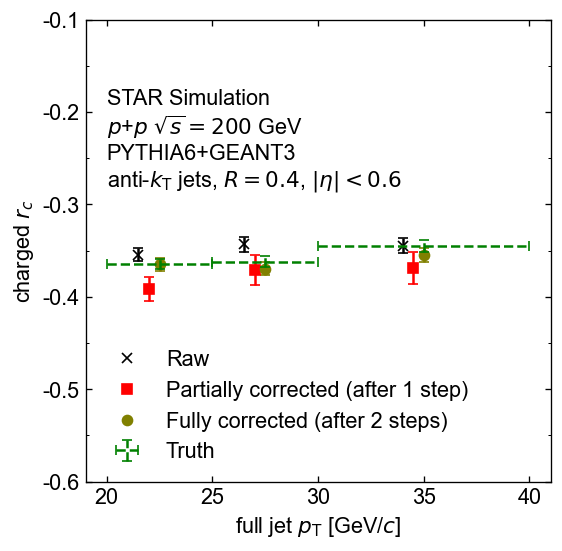

In [84]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([21.5, 26.5, 34.], rc2_allreco_bs_vs_pts_array[1:], yerr=rc2_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none')
plt.errorbar([22, 27, 34.5], rc_fakesubtracted_array[1:], yerr=rc_err_fakesubtracted_array[1:], capsize=3, color='r', ls='none')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='olive', ls='none')
plt.plot([21.5, 26.5, 34.], rc2_allreco_bs_vs_pts_array[1:], color='k', ls='none', marker='x', label='Raw')
plt.plot([22, 27, 34.5], rc_fakesubtracted_array[1:], color='r', ls='none', marker='s', label='Partially corrected (after 1 step)')
plt.plot([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], color='olive', ls='none', marker='o', label='Fully corrected (after 2 steps)')
eb1 = plt.errorbar([22.5, 27.5, 35], rc2_truth_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc2_err_truth_b_vs_pt_array[1:], capsize=3, color='g', ls='none', label='Truth')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV/$c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower left', frameon=False)
plt.text(20, -0.28, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
plt.savefig('rc_vs_pt_closure_shifted.pdf', bbox_inches='tight')